## Problem 1: Visualise data in a static map (10 points)


Create a *static* **thematic map** using the skills you learnt during lesson 5. The map should <br>
contain more than one layer (from at least two different data sets). Pay attention to classification <br>
and visualisation (appropriate colour scheme choice, etc.). Write your code in this notebook, and <br>
store the resulting maps in `.png` format in the `NOTEBOOK_DIRECTORY / "docs"` folder.

### Topic of the map

- Use any of the data sets we have used during the course (travel time data, population grid), or <br>
  any other data set of your interest (for example, [open data sets from Statistics Finland](https://www.stat.fi/org/avoindata/index_en.html), <br>
  or the open geo-data from [the Helsinki Region Infoshare](https://hri.fi/en)). If you download <br>
  data sets, add, commit, and push them to the `DATA_DIRECTORY`. Be sure to include an attribution <br>
  to each data set in your output map!
- Feel free to start from and adapt examples from the course material! You can take one step further <br>
  and add additional analysis to, e.g., the shopping centre dominance or the population within vincinity <br>
  of certain addresses)

### Criteria

- The map has more than one data layer (for instance, the results of an analysis, and the road network <br>
  to illustrate a complex spatial pattern). If (and only if) you think it adds additional value, feel <br>
  free to add a base map (but a base map does not count as an own layer)
- The map portrays the output of an analysis or a classification that adds value beyond just displaying <br>
  the raw data
- The map follows good cartographic practices (appropriate map extent and zoom level, colour scheme, <br>
  legend and data sources, etc.)

### Output

- Save the map(s) in `.png` format in the `NOTEBOOK_DIRECTORY / "docs"` folder, remember to add, commit, <br>
  and push them to the GitHub repository
- Remember to also add, commit, and push input data sets and code

---

In [1]:
import pathlib 
NOTEBOOK_PATH = pathlib.Path().resolve()
DATA_DIRECTORY = NOTEBOOK_PATH / "data"
OUTPUT_DIRECTORY = NOTEBOOK_PATH / "docs"

In [2]:
# ADD YOUR OWN CODE HERE

In [3]:
# Install required libraries
!pip install requests fmiopendata libpysal

In [4]:
# Most necessary imports
import json
import os
import geopandas as gpd
import pandas as pd
import requests
from datetime import datetime
from fmiopendata.wfs import download_stored_query
from statistics import mean
import libpysal
from libpysal.cg.voronoi import voronoi, voronoi_frames
import matplotlib.pyplot as plt
import contextily as cx

os.environ['PROJ_LIB'] = '/path/to/env/share/proj'
#os.environ['GDAL_DATA'] = '/path/to/env/share/'

In [5]:
# Read power generation data from CSV
# Fetched from here: https://data.fingrid.fi/open-data-forms/search/en/
df_power = pd.read_csv(DATA_DIRECTORY / 'wind_power_generation_fingrid.csv', sep=',')
df_power.head()
# Get the row of the wind power generation maximum value
h_max = df_power.iloc[df_power["Wind power generation - hourly data"].idxmax()]
h_max

Start time UTC                         2022-12-12 17:00:00
End time UTC                           2022-12-12 18:00:00
Start time UTC+02:00                   2022-12-12 19:00:00
End time UTC+02:00                     2022-12-12 20:00:00
Wind power generation - hourly data                 4083.0
Name: 19, dtype: object

In [6]:
# Print as a sanity check
print(datetime.fromisoformat(h_max['Start time UTC']))

2022-12-12 17:00:00


In [7]:
# Define start time and end time for the data retrieval time period
start_time = datetime.fromisoformat(h_max['Start time UTC']).isoformat(timespec="seconds") + 'Z'
end_time =   datetime.fromisoformat(h_max['End time UTC']).isoformat(timespec="seconds") + 'Z'
# Print times as a sanity check
print(start_time, end_time)

# Download observation data for all observation stations
# from the defined time period as a time series
obs = download_stored_query("fmi::observations::weather::multipointcoverage",
                            args=["bbox=19.08, 58.84, 31.59, 70.09","starttime=" + start_time, 
                                  "endtime=" + end_time, "timeseries=True"])

2022-12-12T17:00:00Z 2022-12-12T18:00:00Z


In [8]:
# Printing to get idea of the keys and units in the observation data
print(obs.data['Porvoo Kilpilahti satama'].keys())
print(obs.data['Porvoo Kilpilahti satama']['p_sea']['unit'])

dict_keys(['times', 't2m', 'ws_10min', 'wg_10min', 'wd_10min', 'rh', 'td', 'r_1h', 'ri_10min', 'snow_aws', 'p_sea', 'vis', 'n_man', 'wawa'])
hPa


In [9]:
# Print the data type of the data
type(obs)

fmiopendata.multipoint.MultiPoint

In [10]:
# Average all observation data for an hour per station
obs_dict = [{'station': key, 
             'windspeed_avg': mean(obs.data[key]['ws_10min']['values']), # Average windspeed, m/s
             'rh': mean(obs.data[key]['rh']['values']), # Mean relative humidity for hour
             'Tc': mean(obs.data[key]['t2m']['values']), # Temperature in Celsius at 2.00m from the surface
             'p_sea': mean(obs.data[key]['p_sea']['values']), # Sea level air pressure, hPa
             'latitude': obs.location_metadata[key]['latitude'], # Latitude in WRS84
             'longitude': obs.location_metadata[key]['longitude']} for key in obs.data.keys()]

In [11]:
# Create pandas.DataFrame from observations and drop data for stations 
# which have NaN value in any column.
obs_df = pd.DataFrame.from_dict(obs_dict, orient='columns').dropna().reset_index()
obs_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 130 entries, 0 to 129
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   index          130 non-null    int64  
 1   station        130 non-null    object 
 2   windspeed_avg  130 non-null    float64
 3   rh             130 non-null    float64
 4   Tc             130 non-null    float64
 5   p_sea          130 non-null    float64
 6   latitude       130 non-null    float64
 7   longitude      130 non-null    float64
dtypes: float64(6), int64(1), object(1)
memory usage: 8.2+ KB


In [12]:
def saturation_pressure(t_c):
    """
    Approximate saturation pressure at a station
    using Teten's formulas provided by Monteith and Unsworth (2008) (above 0 C)
    and Murray (1967) (below 0C).
    https://en.wikipedia.org/wiki/Tetens_equation#cite_note-Murray1967-3
    """
    if t_c < 0:
        # Murray formula for saturation pressure below 0 Celsius
        return 6.1078*10**((21.875*t_c)/(t_c + 265.5))
    else:
        # Tetens formula for saturation pressure above 0 Celsius
        return 6.1078*10**((17.27*t_c)/(t_c + 237.3))
obs_df['p_saturation'] = obs_df['Tc'].transform(saturation_pressure)
print(obs_df[['p_saturation', 'Tc']].describe())

       p_saturation          Tc
count    130.000000  130.000000
mean       0.849689  -13.042515
std        0.783053    7.034279
min        0.007946  -30.942857
25%        0.243281  -15.967857
50%        0.833197  -10.100820
75%        1.091276   -8.778571
max        4.993865   -1.057143


In [13]:
# Calculate vapor pressure using saturation pressure and relative humidity
obs_df['p_v'] = obs_df['rh']*obs_df['p_saturation']
print(obs_df.head())

   index                          station  windspeed_avg         rh        Tc  \
0      1  Jomala Maarianhamina lentoasema      11.468852  68.885246 -3.829508   
1      2                     Parainen Utö      15.928571  89.571429 -5.914286   
2      3                   Lemland Nyhamn      15.257143  71.285714 -2.871429   
3      4                  Jomala Jomalaby       6.942857  73.571429 -4.028571   
4      5                Hammarland Märket      19.900000  66.142857 -1.057143   

         p_sea  latitude  longitude  p_saturation         p_v  
0  1005.091803  60.12735   19.90038      2.922453  201.313868  
1  1001.542857  59.77909   21.37479      1.938628  173.645693  
2  1004.157143  59.95911   19.95374      3.521407  251.026021  
3  1005.442857  60.17824   19.98686      2.810929  206.804071  
4  1005.671429  60.30098   19.13142      4.993865  330.308504  


In [14]:
def density_humid_air(row):
    """
    Use equation from https://en.wikipedia.org/wiki/Density_of_air#Humid_air
    to calculate density of humid air at a station
    """
    T = row['Tc'] + 273.15 # Temperature in Kelvins
    M_d = 0.0289652 # Molar mass of dry air in kg/mol
    p_v = 100*row['p_v'] # Vapor pressure of water in Pascals
    p_d = 100*row['p_sea'] - p_v # Partial pressure of dry air in Pascals
    M_v = 0.018016 # molar mass of water vapor in kg/mol
    R = 8.31446 # Universal gas constant, J/(K*mol)
    return (p_d*M_d + p_v*M_v) / (R*T)

obs_df['air_density'] = obs_df.apply(density_humid_air, axis=1)
# Sanity check: Colder air should be denser.
print(obs_df[['air_density', 'Tc', 'p_sea']].sort_values('Tc', ascending=True))

     air_density         Tc        p_sea
101     1.477984 -30.942857  1027.800000
109     1.479095 -30.700000  1029.614286
113     1.470556 -30.257143  1025.571429
96      1.464849 -28.793443  1027.875410
120     1.463027 -28.457143  1028.057143
..           ...        ...          ...
0       1.201670  -3.829508  1005.091803
126     1.200955  -3.716393  1005.054098
5       1.174836  -3.528571  1002.314286
2       1.171985  -2.871429  1004.157143
4       1.127737  -1.057143  1005.671429

[130 rows x 3 columns]


In [15]:
rho = obs_df['air_density']
v = obs_df['windspeed_avg']
# Calculate wind power density as defined by Zahariea and Husaru et all (2017),
# https://doi.org/10.1051/matecconf/201711207020
# However, use hourly average of windspeed rather than annual average
obs_df['power_density'] = 0.5*rho*v**3

In [16]:
# Make a GeoDataFrame from the observations and project to EPSG:3067.
obs_gdf = gpd.GeoDataFrame(obs_df, crs='EPSG:4326', 
                           geometry=gpd.GeoSeries.from_xy(obs_df['longitude'], obs_df['latitude'], crs='EPSG:4326')).to_crs('EPSG:3067')
print(obs_gdf.head())
print(obs_gdf.describe())
obs_gdf.explore()

   index                          station  windspeed_avg         rh        Tc  \
0      1  Jomala Maarianhamina lentoasema      11.468852  68.885246 -3.829508   
1      2                     Parainen Utö      15.928571  89.571429 -5.914286   
2      3                   Lemland Nyhamn      15.257143  71.285714 -2.871429   
3      4                  Jomala Jomalaby       6.942857  73.571429 -4.028571   
4      5                Hammarland Märket      19.900000  66.142857 -1.057143   

         p_sea  latitude  longitude  p_saturation         p_v  air_density  \
0  1005.091803  60.12735   19.90038      2.922453  201.313868     1.201670   
1  1001.542857  59.77909   21.37479      1.938628  173.645693     1.220053   
2  1004.157143  59.95911   19.95374      3.521407  251.026021     1.171985   
3  1005.442857  60.17824   19.98686      2.810929  206.804071     1.200327   
4  1005.671429  60.30098   19.13142      4.993865  330.308504     1.127737   

   power_density                        geom

In [17]:
# Get xy point pairs for the observation stations
st_points = [(point.x, point.y) for point in obs_gdf['geometry'].to_list()]

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 130 entries, 0 to 129
Data columns (total 1 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   geometry  130 non-null    geometry
dtypes: geometry(1)
memory usage: 1.1 KB


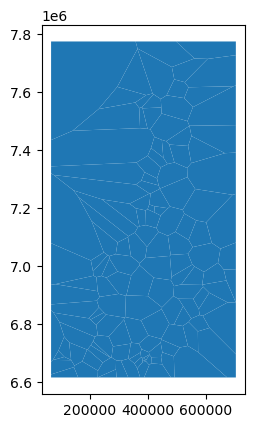

In [18]:
# Calculate voronoi polygons for the observation stations
# so their values can be generalized for wider area.
region_df, point_df = voronoi_frames(st_points)
region_gdf = gpd.GeoDataFrame(region_df, geometry='geometry')
region_gdf.plot()
region_gdf.info()

In [19]:
obs_vor = gpd.GeoDataFrame(obs_df[["station", "windspeed_avg", "rh", "Tc", "p_sea", "power_density"]].join(region_df), crs='EPSG:3067', geometry='geometry')
print(obs_vor.info())
obs_vor.explore(column='power_density', cmap='Blues')

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 130 entries, 0 to 129
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype   
---  ------         --------------  -----   
 0   station        130 non-null    object  
 1   windspeed_avg  130 non-null    float64 
 2   rh             130 non-null    float64 
 3   Tc             130 non-null    float64 
 4   p_sea          130 non-null    float64 
 5   power_density  130 non-null    float64 
 6   geometry       130 non-null    geometry
dtypes: float64(5), geometry(1), object(1)
memory usage: 7.2+ KB
None


In [20]:
def get_features(req_url, params={}, auth=None, features=[]):
    """
    Dirty recursive function that fetches feature data from a OGC Api Features compliant server
    """
    response = requests.request(method='GET', url=req_url, params=params, auth=auth) 
    json_ob = response.json()
    feat = json_ob['features'] # Get OGC features from the json response
    if (len(feat) > 0 and len(feat) == json_ob['numberReturned']):
        # If there are features and json has numberReturned tag
        # add features to the list of features
        features += feat
    links = json_ob['links']
    if (len(links) >= 2 and links[1]['rel'] == 'next'):
        # If the response json has link to the next data page, 
        # follow the link, otherwise, return already fetched 
        # features
        next_url = links[1]['href']
        return get_features(next_url, params, auth, features)
    else: 
        return features
        
feats = get_features('https://avoin-paikkatieto.maanmittauslaitos.fi/maastotiedot/features/v1/collections/tuulivoimala/items?', 
                     auth=('74ee1b32-8fa3-4782-bb62-04a02beffafa', None), 
                     params={'crs': 'http://www.opengis.net/def/crs/EPSG/0/3067'})
#print(feats)
print(len(feats))
# Create a geopandas.GeoDataFrame from the OGC Features
windmills_gdf = gpd.GeoDataFrame.from_features(feats, crs='EPSG:3067')
print(windmills_gdf.head())

1531
                         geometry     mtk_id  sijaintitarkkuus  \
0  POINT (197977.475 6756515.092)  397092977             20000   
1  POINT (444115.192 6683255.785)  176595799             15000   
2  POINT (262451.462 6742786.382)  119773300              5000   
3  POINT (206889.326 6692286.389)  328242470              5000   
4  POINT (221794.197 6704021.777)  135787246              5000   

   korkeustarkkuus  aineistolahde     alkupvm  suunta  kohderyhma  kohdeluokka  
0              201              1  2013-07-08       0          47        45500  
1              201              1  2013-11-14       0          47        45500  
2              201              1  2013-07-02       0          47        45500  
3           100001              1  2013-06-27       0          47        45500  
4              201              1  2013-12-12       0          47        45500  


In [21]:
# Explore wind turbines
windmills_gdf.explore(marker_kwds={'radius':0.2})

In [22]:
# Spatially join voronoi polygons for the observation stations into wind turbines
sjoined = windmills_gdf.sjoin(obs_vor)
# Count the number of wind turbines by voronoi polygon
counts = sjoined[['mtk_id', 'station']].groupby(['station']).count().rename({'mtk_id': 'wm_count'}, axis=1)
# Join counts by station name
wm_count_vor = obs_vor.merge(on='station', right=counts)
# Calculate the percentage of wind turbines of total amount by voronoi polygon
wm_count_vor['share_of_total'] = (wm_count_vor['wm_count'] / len(feats)) * 100
# Sanity check that the sum of percentages is reasonably close to 100.
print(wm_count_vor['share_of_total'].sum())
#wm_count_vor['Windmills / km^2'] = wm_count_vor['wm_count'] / (wm_count_vor.geometry.area / 1e6)
#print(wm_count_vor[['station', 'Windmills / km^2']].sort_values('Windmills / km^2', ascending=False).head())
# Change the geometry of the polygon into its centroid and make a GeoDataFrame
wm_count_vor.geometry = wm_count_vor.geometry.centroid
wm_count_p = wm_count_vor 
wm_count_p.head()

100.00000000000001


,station,windspeed_avg,rh,Tc,p_sea,power_density,geometry,wm_count,share_of_total
0,Jomala Maarianhamina lentoasema,11.468852,68.885246,-3.829508,1005.091803,906.390378,POINT (91568.566 6689636.129),2,0.130634
1,Parainen Utö,15.928571,89.571429,-5.914286,1001.542857,2465.353233,POINT (184884.173 6638069.706),3,0.195950
2,Lemland Nyhamn,15.257143,71.285714,-2.871429,1004.157143,2081.189256,POINT (99837.756 6655539.316),7,0.457218
3,Jomala Jomalaby,6.942857,73.571429,-4.028571,1005.442857,200.855787,POINT (115305.353 6713575.023),16,1.045069
4,Parainen Fagerholm,11.757143,86.142857,-7.271429,1002.428571,1016.032941,POINT (207763.844 6673417.948),4,0.261267


<AxesSubplot: >

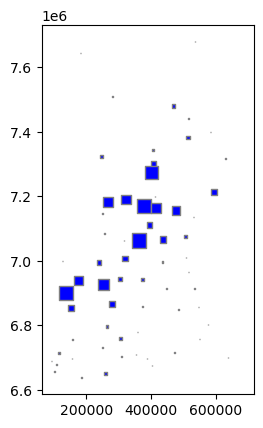

In [23]:
#wm_count_p['test'] = wm_count_p['Windmills / km^2'] / wm_count_p['Windmills / km^2'].max()
# Test proportional size markers
wm_count_p.plot(marker='s', color='Blue', edgecolors='gray', markersize=(wm_count_p['share_of_total']**2)*2.5 )

0       2.000000
34      2.000000
35      2.000000
36      2.000000
38      2.000000
         ...    
30    177.063526
68    269.522402
59    286.813646
29    298.639781
54    304.642441
Name: share_of_total, Length: 86, dtype: float64
<class 'matplotlib.axes._subplots.AxesSubplot'>


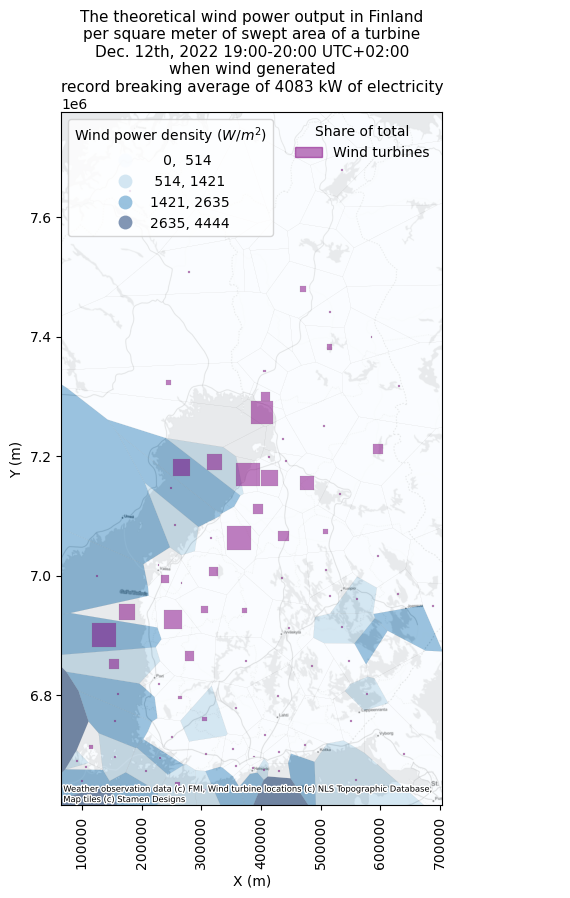

In [24]:
# Create subplot 
fig, ax = plt.subplots(1, 1, figsize=(12,9))

# Plot the voronoi polygons for the observation stations
# using the power density column and natural breaks
obs_plt = obs_vor.plot(ax=ax, linewidth=0.05, edgecolor='Grey', 
             cmap='Blues', column='power_density', 
             scheme='NaturalBreaks', k=4, alpha=0.5, legend=True,
                       legend_kwds={'loc':'upper left', 'title':'Wind power density (${W}/{m^2}$)', 'fmt': '{:.0f}'})
# Get plot bounds in map coordinates
minx, miny, maxx, maxy = obs_vor.total_bounds
# Set limits and labels for both axes
ax.set_xlim(minx, maxx)
ax.set_xlabel('X (m)')
ax.set_ylim(miny, maxy)
ax.set_ylabel('Y (m)')
# Rotate the labels of X axis
plt.xticks(rotation = 90)

# Calculate size for proportional symbols
ss=(wm_count_p['share_of_total']**2)*7
# It appeared that markersize below 2 pt is barely visible in the map, 
# so all values below that will be turned to 2 pt. 
ss=ss.transform(lambda x: max(x,2))
print(ss.sort_values())
# Plot the wind turbine share on the map using proportional markers
wm_plot = wm_count_p.plot(kind='geo', ax=ax, marker='s', color='Purple', edgecolors='gray', linewidth=0.2, 
                          legend=True, markersize=ss, alpha=0.5
)
print(type(wm_plot))

# Additional imports for the legend generation
from matplotlib.legend import Legend
import matplotlib.patches as mpatches

# Create Patch for the second legend and then create the legend for wind turbine share
patch = mpatches.Rectangle(xy=(0,0), width=6, height=6, color='Purple', alpha=0.5)
leg = Legend(ax, [patch, wm_plot], ['Wind turbines'], title='Share of total', loc='upper right', frameon=False)
ax.add_artist(leg) # Add second legend

# Create title for the figure
plt.title((
    'The theoretical wind power output in Finland\n'
    'per square meter of swept area of a turbine\n'
    'Dec. 12th, 2022 19:00-20:00 UTC+02:00\n'
    'when wind generated\n' 
    'record breaking average of {power} kW of electricity' 
    ).format(power=round(h_max["Wind power generation - hourly data"])),
    wrap=True, multialignment='center', clip_on=True, fontsize=11
) 
# Add Stamen basemap and attributions
cx.add_basemap(ax, crs=obs_vor.crs.to_string(), source=cx.providers.Stamen.TonerLite, 
               attribution="Weather observation data (c) FMI, Wind turbine locations (c) NLS Topographic Database, Map tiles (c) Stamen Designs",
               attribution_size=6)

In [25]:
# Save the figure
fig.savefig(OUTPUT_DIRECTORY / 'Theoretical_wind_power_output_Finland_2022-12-12.png', dpi=300, bbox_inches='tight')